In [ ]:
import random
random.seed(42)

import torch

import numpy as np
import pyomo.environ as pyo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyomo.environ import *
from utils import generate_simple_synthetic_data, const_embed, load_case_study_data, generate_data_by_ids
from trainer import Trainer

np.random.seed(43)

LOAD_CASE_STUDY = False
DATA_BY_ID = True

In [2]:
if LOAD_CASE_STUDY:
    print("Loading case study data...")
    X, y, val_ind, test_ind = load_case_study_data()

elif DATA_BY_ID:
    print("Loading data by IDs...")
    df = generate_data_by_ids(n_ids=50, n_prices_per_id=200)
    X = df[['id', 'x1', 'x2', 'price']]
    y = df['y']
    print(X.head())
    print(y.head())
    
else:
    X, y, true_mean, true_std = generate_simple_synthetic_data(n_samples=1000)

    print(X.head())
    print(y.head())


Loading data by IDs...
   id       x1        x2      price
0   1  0.37454  0.969585  10.628584
1   1  0.37454  0.969585  22.728208
2   1  0.37454  0.969585  16.287120
3   1  0.37454  0.969585  20.171414
4   1  0.37454  0.969585  28.151329
0    8.659758
1    0.734286
2    7.501485
3    2.911887
4    0.000000
Name: y, dtype: float64


In [3]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

'''model_config = {
    'hidden_layers': 1,
    'hidden_size': 5,
    'drop': 0.2
    }

training_config = {
    'lr': 0.01,
    'wd': 0.0001,
    'batchsize': 64,
    'iters': 500,
    'patience': 20
    }'''

config = {
    # Model config
    'hidden_layers': 1,
    'hidden_size': 30,
    'drop': 0.05,

    # Training config
    'lr': 0.001,
    'wd': 0,
    'batchsize': 64,
    'iters': 5000,
    'patience': 500
}

trainer = Trainer(X, y, config, device=device)

if LOAD_CASE_STUDY:
    trainer.set_data_partitions(X_train=X[(~X.index.isin(val_ind)) & (~X.index.isin(test_ind))], y_train=y[(~y.index.isin(val_ind)) & (~y.index.isin(test_ind))], X_val=X[X.index.isin(val_ind)], y_val=y[y.index.isin(val_ind)], X_test=X[X.index.isin(test_ind)], y_test=y[y.index.isin(test_ind)])
elif not DATA_BY_ID:
    trainer.create_data_partitions(val_size=0.2, test_size=0.2, random_state=42)
else:
    trainer = Trainer(X, y, config, device=device, id_col='id')
    trainer.create_data_partitions_by_id(val_size=0.2, test_size=0.2, random_state=42)
    

print("X_train shape: ", trainer.X_train.shape)
print("X_val shape: ", trainer.X_val.shape)
print("X_test shape: ", trainer.X_test.shape)

trainer.train()

trainer.test()

X_train shape:  (6000, 3)
X_val shape:  (2000, 3)
X_test shape:  (2000, 3)
Validation loss improved from inf to 1.8127 in epoch 1. Saving model...
Epoch 1/5000 - Train Loss: 848.3994, Val Loss: 1.8127
Validation loss improved from 1.8127 to 0.7170 in epoch 2. Saving model...
Validation loss improved from 0.7170 to 0.3710 in epoch 3. Saving model...
Validation loss improved from 0.3710 to 0.1809 in epoch 4. Saving model...
Validation loss improved from 0.1809 to 0.0721 in epoch 5. Saving model...
Validation loss improved from 0.0721 to -0.0082 in epoch 6. Saving model...
Validation loss improved from -0.0082 to -0.0772 in epoch 7. Saving model...
Validation loss improved from -0.0772 to -0.1442 in epoch 8. Saving model...
Validation loss improved from -0.1442 to -0.2117 in epoch 9. Saving model...
Validation loss improved from -0.2117 to -0.2774 in epoch 10. Saving model...
Validation loss improved from -0.2774 to -0.3434 in epoch 11. Saving model...
Epoch 11/5000 - Train Loss: -0.2950,

In [4]:
trainer.model

distModel(
  (input_layer): Linear(in_features=3, out_features=30, bias=True)
  (hidden_layers): ModuleList(
    (0): Linear(in_features=30, out_features=30, bias=True)
  )
  (output_mean_layer): Linear(in_features=30, out_features=1, bias=True)
  (output_sd_layer): Linear(in_features=30, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.05, inplace=False)
)

In [5]:
#trainer.predict(X=trainer.X_test)

In [6]:
trainer.evaluate_gaussian_nll()
trainer.evaluate_standardized_residuals()

Baseline Gaussian NLL Loss: 0.6334
Model Gaussian NLL Loss: -1.1552
KS test against N(0,1): statistic = 0.0272, p-value = 0.1025
✅ The standardized residuals do not significantly differ from a standard normal distribution — model variance estimates appear well-calibrated.
Saved: residual_diagnostics\z_histogram.png
Saved: residual_diagnostics\z_qqplot.png


(np.float64(0.02717130176237935), np.float64(0.10245015278263037))

In [7]:
'''# Inputs
x = np.array([[-1.266313, -0.405118, 0.612491]])

# Extract weights from model
state_dict = trainer.model.state_dict()
w0 = state_dict['input_layer.weight'].cpu().numpy()
b0 = state_dict['input_layer.bias'].cpu().numpy()

w1 = state_dict['hidden_layers.0.weight'].cpu().numpy()
b1 = state_dict['hidden_layers.0.bias'].cpu().numpy()

w_mean = state_dict['output_mean_layer.weight'].cpu().numpy()
b_mean = state_dict['output_mean_layer.bias'].cpu().numpy()

w_sd = state_dict['output_sd_layer.weight'].cpu().numpy()
b_sd = state_dict['output_sd_layer.bias'].cpu().numpy()

# Manual forward pass
def relu(x): return np.maximum(0, x)

h0 = relu(x.dot(w0.T) + b0)
h1 = relu(h0.dot(w1.T) + b1)
mean = h1.dot(w_mean.T) + b_mean
sd = relu(h1.dot(w_sd.T) + b_sd)

print("Manual mean:", mean)
print("Manual std:", sd)'''

'# Inputs\nx = np.array([[-1.266313, -0.405118, 0.612491]])\n\n# Extract weights from model\nstate_dict = trainer.model.state_dict()\nw0 = state_dict[\'input_layer.weight\'].cpu().numpy()\nb0 = state_dict[\'input_layer.bias\'].cpu().numpy()\n\nw1 = state_dict[\'hidden_layers.0.weight\'].cpu().numpy()\nb1 = state_dict[\'hidden_layers.0.bias\'].cpu().numpy()\n\nw_mean = state_dict[\'output_mean_layer.weight\'].cpu().numpy()\nb_mean = state_dict[\'output_mean_layer.bias\'].cpu().numpy()\n\nw_sd = state_dict[\'output_sd_layer.weight\'].cpu().numpy()\nb_sd = state_dict[\'output_sd_layer.bias\'].cpu().numpy()\n\n# Manual forward pass\ndef relu(x): return np.maximum(0, x)\n\nh0 = relu(x.dot(w0.T) + b0)\nh1 = relu(h0.dot(w1.T) + b1)\nmean = h1.dot(w_mean.T) + b_mean\nsd = relu(h1.dot(w_sd.T) + b_sd)\n\nprint("Manual mean:", mean)\nprint("Manual std:", sd)'

In [8]:
cons = trainer.constraint_build()
cons.to_csv('constraints.csv')

In [9]:
cons = pd.read_csv('constraints.csv', index_col=0)
pd.set_option('display.precision', 10)
cons

,intercept,layer,node,node_0,node_1,node_2,node_3,node_4,node_5,node_6,...,node_20,node_21,node_22,node_23,node_24,node_25,node_26,node_27,node_28,node_29
0,0.60394174,0,0,0.5893439700,0.0050662514,0.014447403,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-0.60249966,0,1,-0.3375694800,-0.3889905200,-0.138016200,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.42631036,0,2,0.1374044100,-0.3783966000,-0.179507050,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,-0.34266114,0,3,0.1186275100,-0.4381725000,-0.205153540,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,-0.49108550,0,4,0.0012763765,-0.1736643200,0.432608200,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27,0.14092919,1,27,-0.5521416000,-0.1408915200,0.330637630,-1.98668970,-0.1856544600,-0.3420265600,0.13197517,...,-0.015568845,-0.198857520,-0.0033442539,0.2763721300,0.116420545,-0.0389376170,-0.0753213200,-1.23659650,-0.038738010,0.237538490
28,0.14333622,1,28,0.1155963100,0.4525239800,-0.072451010,-0.21653222,0.0742148000,0.1413656600,-0.11850513,...,0.065932370,-0.608024700,0.0665072700,-0.0639749900,0.345250130,0.0053856513,-0.4182930300,-0.09909848,0.242444840,-0.339007600
29,0.13829751,1,29,0.0317075330,0.8499985300,0.098572270,0.11542407,-0.0888095650,-0.2480883400,-0.75175494,...,-0.164241700,-0.334750000,-0.1992463600,0.0581116230,0.360782650,0.0092681250,-0.0030006533,-0.17571524,0.215885400,-0.175353840
0,-0.54166480,2,0,-0.0741375240,0.2457404300,-0.152924760,-0.11237042,0.3389561000,0.1815341600,0.13796750,...,0.255436400,0.058997914,0.1213216600,0.3324655600,-0.091763250,0.4922699300,-0.1152199360,0.47740590,-0.059904017,-0.080613930


In [10]:

'''#contextual_var = trainer.X_test
contextual_var = trainer.X_test.iloc[[0]]
contextual_var.reset_index(drop=True, inplace=True)
contextual_var'''

'#contextual_var = trainer.X_test\ncontextual_var = trainer.X_test.iloc[[0]]\ncontextual_var.reset_index(drop=True, inplace=True)\ncontextual_var'

In [11]:
'''row = pd.DataFrame([{
    'x1': -1.266313,
    'x2': -0.405118,
    'price': 30.0
}])

def preict_one_row(row):
    # Predict
    mean_pred, sd_pred = trainer.predict(row, unscale=True)
    print("Mean prediction:", mean_pred)
    print("Standard deviation prediction:", sd_pred)

preict_one_row(row)'''

'row = pd.DataFrame([{\n    \'x1\': -1.266313,\n    \'x2\': -0.405118,\n    \'price\': 30.0\n}])\n\ndef preict_one_row(row):\n    # Predict\n    mean_pred, sd_pred = trainer.predict(row, unscale=True)\n    print("Mean prediction:", mean_pred)\n    print("Standard deviation prediction:", sd_pred)\n\npreict_one_row(row)'

In [56]:
def model_definition(contextual_var, n_sc, n_preds):
    model = pyo.ConcreteModel()
    
    model.N = pyo.RangeSet(0,n_preds-1)
    model.W = pyo.RangeSet(1,n_sc) # scenarios

    pi = [1/n_sc for i in range(n_sc)]

    model.var_ind = pyo.Set(initialize=contextual_var.columns.sort_values())

    model.x = pyo.Var(model.var_ind, model.N) # price

    model.y = pyo.Var(pyo.Any, dense=False, domain=pyo.Reals)
    model.y_int = pyo.Var(model.N, model.W, domain=pyo.Integers)

    model.rent = pyo.Var(model.W, within=pyo.Reals) # rentabilidad per scenario

    #definition of the objective function
    def obj_expression(model):
        return sum(pi[w-1] * model.rent[w] for w in model.W)
    model.OBJ = pyo.Objective(rule=obj_expression, sense=pyo.maximize)

    #################
    ## Constraints ##
    #################

    # rentability constraint continuous y
    '''def rent_expression(model, w):
        return model.rent[w] == sum(model.y['demand', n, w]*model.x['price',n] for n in model.N)
    model.rent_expression = pyo.Constraint(model.W, rule=rent_expression)'''

    # rentability constraint integer y
    def rent_expression_int(model, w):
        return model.rent[w] == sum(model.y_int[n, w]*model.x['price',n] for n in model.N)
    model.rent_expression_int = pyo.Constraint(model.W, rule=rent_expression_int)

    # integer demand constraint
    # Upper bound constraint
    def round_y_upper(model, n, w):
        return model.y_int[n, w] <= model.y['demand', n, w] + 0.5
    model.round_y_upper = pyo.Constraint(model.N, model.W, rule=round_y_upper)

    # Lower bound constraint
    def round_y_lower(model, n, w):
        return model.y_int[n, w] >= model.y['demand', n, w] - 0.5
    model.round_y_lower = pyo.Constraint(model.N, model.W, rule=round_y_lower)

    #constraint for fixing contextual information
    def contextual_info(model,x_ind,n):
        if x_ind=='price':
            return pyo.Constraint.Skip
        else:
            return model.x[x_ind,n] == contextual_var.loc[n,x_ind]
    model.const9 = pyo.Constraint(model.var_ind, model.N, rule=contextual_info)

    P_max = 30
    # max price constraint for each price
    def max_price_expression(model, n):
        return model.x['price', n] <= P_max

    model.max_price_expression = pyo.Constraint(model.N, rule=max_price_expression)

    def min_price_expression(model, n):
        return model.x['price', n] >= 0
    model.min_price_expression = pyo.Constraint(model.N, rule=min_price_expression)

    return model


In [42]:
trainer.test_ids

array([14, 47,  7, 40, 33, 49,  5, 46, 48, 42])

In [92]:
n_preds = 5
n_sc =  50

if DATA_BY_ID:
    ids = trainer.test_ids[:n_preds]
    contextual_var = trainer.X[trainer.X['id'].isin(ids)]
    contextual_var = contextual_var.drop_duplicates(subset='id', keep='first').drop(columns='id')
else:
    contextual_var = trainer.X[trainer.X.index.isin(trainer.test_indices)]
    contextual_var = contextual_var.iloc[:n_preds]

contextual_var.reset_index(drop=True, inplace=True)
contextual_var

,price,x1,x2
0,17.9567325100,0.0580836122,0.0884925021
1,19.1912595501,0.2123391107,0.3567533267
2,17.3866033764,0.0650515930,0.3308980249
3,16.6719916168,0.4401524937,0.4722149252
4,26.3407955722,0.3117110761,0.5227328294


In [28]:
'''n_preds = 3
n_sc =  30

contextual_var = trainer.X_test.iloc[:n_preds]
contextual_var.reset_index(drop=True, inplace=True)
contextual_var'''

'n_preds = 3\nn_sc =  30\n\ncontextual_var = trainer.X_test.iloc[:n_preds]\ncontextual_var.reset_index(drop=True, inplace=True)\ncontextual_var'

In [81]:
model = model_definition(contextual_var, n_sc, n_preds)
const_embed(model=trainer, opt_model=model, constaints=cons, outcome='demand', n_scenarios=n_sc, n_preds=n_preds)

In [82]:
opt = pyo.SolverFactory('gurobi_direct')
opt.options['threads'] = 0
opt.options['NonConvex'] = 2
results = opt.solve(model, tee=True)

Set parameter OutputFlag to value 1
Set parameter Threads to value 0
Set parameter NonConvex to value 2
Gurobi Optimizer version 12.0.2 build v12.0.2rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i5-13500, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Non-default parameters:
NonConvex  2

Optimize a model with 2172 rows, 1750 columns and 8892 nonzeros
Model fingerprint: 0x7baa7e28
Model has 300 quadratic constraints
Variable types: 1030 continuous, 720 integer (120 binary)
Coefficient statistics:
  Matrix range     [1e-05, 1e+03]
  QMatrix range    [1e+00, 1e+00]
  QLMatrix range   [1e+00, 1e+00]
  Objective range  [3e-03, 3e-03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e-05, 1e+03]
Presolve removed 662 rows and 944 columns
Presolve time: 0.38s
Presolved: 2711 rows, 1408 columns, 10641 nonzeros
Presolved model has 600 bilinear constraint(s)

Solving non-convex MIQCP

Variable ty

In [18]:
'''print(value(model.x['price', 0]))
print((value(model.x['price', 0]) * trainer.X_std[0]) + trainer.X_mean[0])
print((value(model.x['price', 0] - trainer.X_mean[0])) / trainer.X_std[0])'''

"print(value(model.x['price', 0]))\nprint((value(model.x['price', 0]) * trainer.X_std[0]) + trainer.X_mean[0])\nprint((value(model.x['price', 0] - trainer.X_mean[0])) / trainer.X_std[0])"

In [70]:
for c in model.component_objects(Constraint, active=True):
    print(f"Constraint component: {c.name}")
    for index in c:
        print(f"  {index}: {c[index].expr}")

Constraint component: rent_expression_int
  1: rent[1]  ==  y_int[0,1]*x[price,0]
  2: rent[2]  ==  y_int[0,2]*x[price,0]
  3: rent[3]  ==  y_int[0,3]*x[price,0]
  4: rent[4]  ==  y_int[0,4]*x[price,0]
  5: rent[5]  ==  y_int[0,5]*x[price,0]
  6: rent[6]  ==  y_int[0,6]*x[price,0]
  7: rent[7]  ==  y_int[0,7]*x[price,0]
  8: rent[8]  ==  y_int[0,8]*x[price,0]
  9: rent[9]  ==  y_int[0,9]*x[price,0]
  10: rent[10]  ==  y_int[0,10]*x[price,0]
  11: rent[11]  ==  y_int[0,11]*x[price,0]
  12: rent[12]  ==  y_int[0,12]*x[price,0]
  13: rent[13]  ==  y_int[0,13]*x[price,0]
  14: rent[14]  ==  y_int[0,14]*x[price,0]
  15: rent[15]  ==  y_int[0,15]*x[price,0]
  16: rent[16]  ==  y_int[0,16]*x[price,0]
  17: rent[17]  ==  y_int[0,17]*x[price,0]
  18: rent[18]  ==  y_int[0,18]*x[price,0]
  19: rent[19]  ==  y_int[0,19]*x[price,0]
  20: rent[20]  ==  y_int[0,20]*x[price,0]
  21: rent[21]  ==  y_int[0,21]*x[price,0]
  22: rent[22]  ==  y_int[0,22]*x[price,0]
  23: rent[23]  ==  y_int[0,23]*x[price

In [20]:
'''# Inputs
x = np.array([[-1.266313, -0.405118, 0.612491]])

# Extract weights from model
state_dict = trainer.model.state_dict()
w0 = state_dict['input_layer.weight'].cpu().numpy()
b0 = state_dict['input_layer.bias'].cpu().numpy()

#w1 = state_dict['hidden_layers.0.weight'].cpu().numpy()
#b1 = state_dict['hidden_layers.0.bias'].cpu().numpy()

w_mean = state_dict['output_mean_layer.weight'].cpu().numpy()
b_mean = state_dict['output_mean_layer.bias'].cpu().numpy()

w_sd = state_dict['output_sd_layer.weight'].cpu().numpy()
b_sd = state_dict['output_sd_layer.bias'].cpu().numpy()

# Manual forward pass
def relu(x): return np.maximum(0, x)

h0 = relu(x.dot(w0.T) + b0)
#h1 = relu(h0.dot(w1.T) + b1)
mean = h0.dot(w_mean.T) + b_mean
sd = relu(h0.dot(w_sd.T) + b_sd)

print("Manual mean:", mean)
print("Manual std:", sd)'''

'# Inputs\nx = np.array([[-1.266313, -0.405118, 0.612491]])\n\n# Extract weights from model\nstate_dict = trainer.model.state_dict()\nw0 = state_dict[\'input_layer.weight\'].cpu().numpy()\nb0 = state_dict[\'input_layer.bias\'].cpu().numpy()\n\n#w1 = state_dict[\'hidden_layers.0.weight\'].cpu().numpy()\n#b1 = state_dict[\'hidden_layers.0.bias\'].cpu().numpy()\n\nw_mean = state_dict[\'output_mean_layer.weight\'].cpu().numpy()\nb_mean = state_dict[\'output_mean_layer.bias\'].cpu().numpy()\n\nw_sd = state_dict[\'output_sd_layer.weight\'].cpu().numpy()\nb_sd = state_dict[\'output_sd_layer.bias\'].cpu().numpy()\n\n# Manual forward pass\ndef relu(x): return np.maximum(0, x)\n\nh0 = relu(x.dot(w0.T) + b0)\n#h1 = relu(h0.dot(w1.T) + b1)\nmean = h0.dot(w_mean.T) + b_mean\nsd = relu(h0.dot(w_sd.T) + b_sd)\n\nprint("Manual mean:", mean)\nprint("Manual std:", sd)'

In [71]:
contextual_var

,price,x1,x2
0,19.1912595501,0.2123391107,0.3567533267


In [22]:
'''row = pd.DataFrame([{
    'price': 14.838617787184095,
    'x1': 0.7319939418,
    'x2': 0.8729458359,
}])

row = row.reindex(sorted(row.columns), axis=1)

def preict_one_row(row):
    # Predict
    mean_pred, sd_pred = trainer.predict(row, unscale=False, scale_data=True)
    print("Mean prediction:", mean_pred)
    print("Standard deviation prediction:", sd_pred)

preict_one_row(row)'''

'row = pd.DataFrame([{\n    \'price\': 14.838617787184095,\n    \'x1\': 0.7319939418,\n    \'x2\': 0.8729458359,\n}])\n\nrow = row.reindex(sorted(row.columns), axis=1)\n\ndef preict_one_row(row):\n    # Predict\n    mean_pred, sd_pred = trainer.predict(row, unscale=False, scale_data=True)\n    print("Mean prediction:", mean_pred)\n    print("Standard deviation prediction:", sd_pred)\n\npreict_one_row(row)'

In [83]:
for n in model.N:
    print("&"*50)
    print("Establecimiento ", n)
    opt_price = value(model.x['price',n])
    total_demand = 0
    total_demand_int = 0
    for x in range(n_sc):
        total_demand += value(model.y['demand', n, x+1])
        total_demand_int += value(model.y_int[n, x+1])
        #print("demand: ", value(model.y['demand', 0, x+1]))
    print("Average demand: ", total_demand/n_sc)
    print("Average demand int: ", total_demand_int/n_sc)
    opt_mean = value(model.y['demand', n,'mean'])
    opt_sd = value(model.y['demand', n,'sd'])
    opt_profit = value(model.OBJ)

    print(f"Optimal profit: {opt_profit}")
    print(f"Optimal price: {opt_price}")
    print(f"Optimal mean: {opt_mean}")
    print(f"Optimal sd: {opt_sd}")
    print("&"*50)

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establecimiento  0
Average demand:  3.286032258760267
Average demand int:  3.3233333333333333
Optimal profit: 112.10226785893705
Optimal price: 14.193350950487503
Optimal mean: 0.19200167122766576
Optimal sd: 0.28362810918671555
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establecimiento  1
Average demand:  4.852265026739763
Average demand int:  4.8566666666666665
Optimal profit: 112.10226785893705
Optimal price: 13.369876087882686
Optimal mean: 0.7164632902558846
Optimal sd: 0.2671569163052981
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&


In [73]:
for n in model.N:
    print("&"*50)
    print("Establecimiento ", n)
    opt_price = value(model.x['price',n])
    total_demand = 0
    for x in range(n_sc):
        total_demand += value(model.y['demand', n, x+1])
        print("demand: ", value(model.y['demand', 0, x+1]))
        print("demand: ", value(model.y_int[ 0, x+1]))

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establecimiento  0
demand:  4.7581684731206995
demand:  5.0
demand:  3.6019271277731724
demand:  4.0
demand:  4.09241865904227
demand:  4.0
demand:  5.162410041596196
demand:  5.0
demand:  4.845915325485731
demand:  5.0
demand:  2.434207296788421
demand:  2.0
demand:  4.068131004886881
demand:  4.0
demand:  3.1343810873751474
demand:  3.0
demand:  3.1751903523638694
demand:  3.0
demand:  3.610778728598668
demand:  4.0
demand:  3.3848069340856237
demand:  3.0
demand:  4.495553634416064
demand:  4.0
demand:  3.907863385428042
demand:  4.0
demand:  3.3658440042900324
demand:  3.0
demand:  3.638978885663997
demand:  4.0
demand:  3.545566302338222
demand:  4.0
demand:  4.529298781048212
demand:  5.0
demand:  3.0887712724849794
demand:  3.0
demand:  3.5280970468268524
demand:  4.0
demand:  2.5386348880411065
demand:  3.0
demand:  1.0983983782837305
demand:  1.0
demand:  3.8167988778834427
demand:  4.0
demand:  3.9955193840868333
demand:  4.0

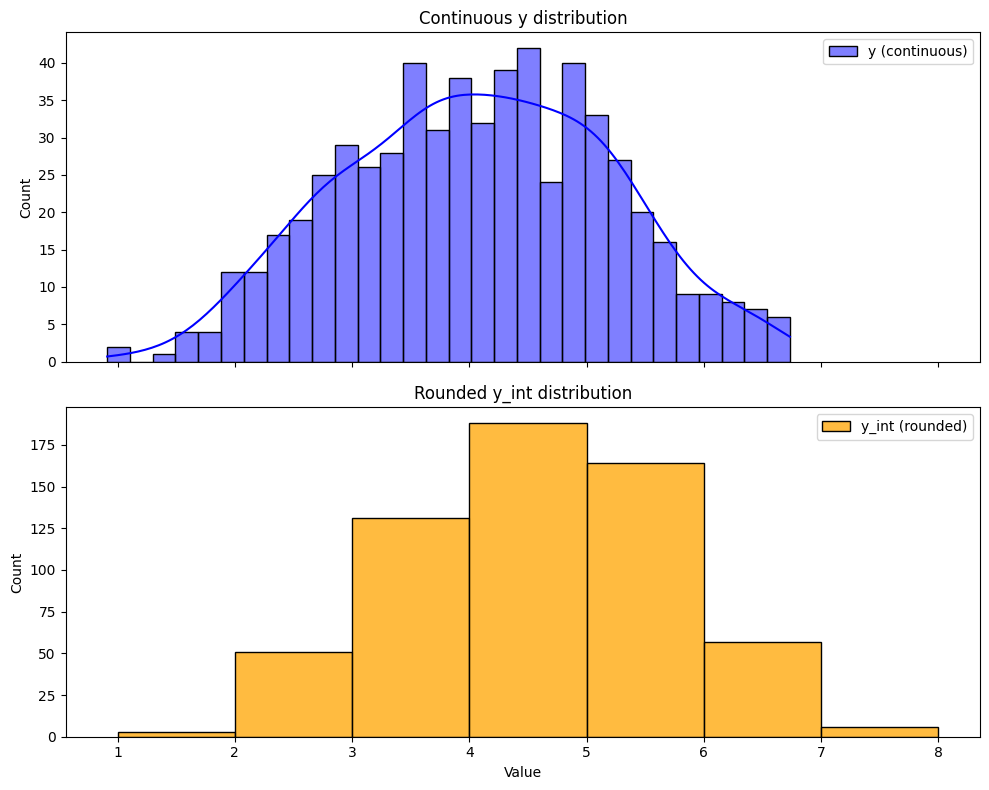

In [ ]:
# ALL DEMANDS TOGETHER
y_vals = [pyo.value(model.y['demand', n, w]) for n in model.N for w in model.W]
y_int_vals = [pyo.value(model.y_int[n, w]) for n in model.N for w in model.W]

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

sns.histplot(y_vals, kde=True, color='blue', label='y (continuous)', bins=30, ax=ax[0])
ax[0].legend()
ax[0].set_title('Continuous y distribution')

sns.histplot(y_int_vals, kde=False, color='orange', label='y_int (rounded)', 
             bins=range(int(min(y_int_vals)), int(max(y_int_vals))+2), ax=ax[1])
ax[1].legend()
ax[1].set_title('Rounded y_int distribution')

plt.xlabel('Value')
plt.tight_layout()
plt.show()

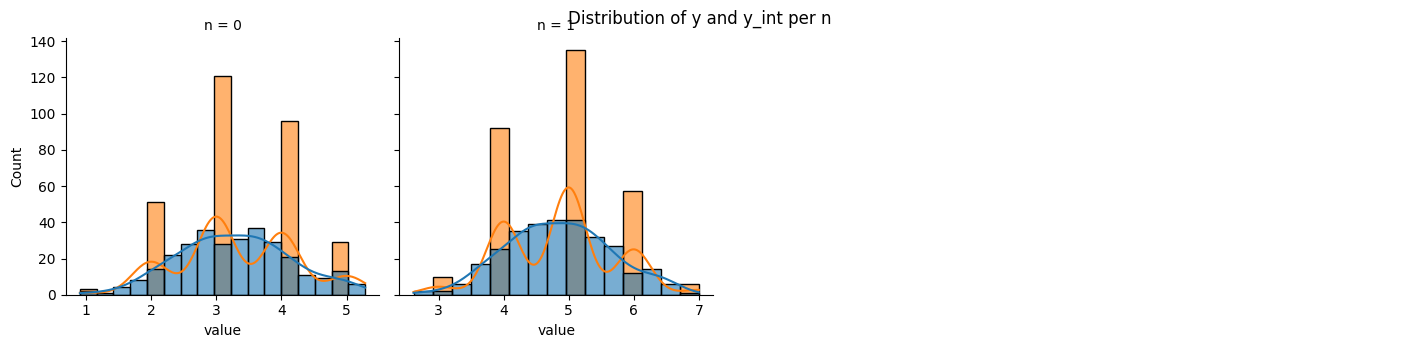

In [ ]:
# DEMAND BY ID

# Create a DataFrame from your data
data = []
for n in model.N:
    for w in model.W:
        y_val = pyo.value(model.y['demand', n, w])
        y_int_val = pyo.value(model.y_int[n, w])
        data.append({'n': n, 'w': w, 'y': y_val, 'y_int': y_int_val})
df = pd.DataFrame(data)

# Melt the DataFrame to long format for seaborn
df_melted = df.melt(id_vars=['n', 'w'], value_vars=['y', 'y_int'], var_name='type', value_name='value')

# Plot using FacetGrid (one subplot per n)
g = sns.FacetGrid(df_melted, col='n', col_wrap=4, sharex=False, height=3.5)
g.map_dataframe(sns.histplot, x='value', hue='type', kde=True if 'y' in df_melted['type'].unique() else False, alpha=0.6)
g.add_legend()
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Distribution of y and y_int per n")
plt.show()


# EXPERIMENTS

n_sc=0: price=12.86, time=0.04s
n_sc=10: price=14.43, time=0.51s
n_sc=20: price=13.96, time=0.55s
n_sc=30: price=14.13, time=0.48s
n_sc=40: price=14.13, time=0.52s
n_sc=50: price=14.13, time=0.74s
n_sc=60: price=14.13, time=0.73s
n_sc=70: price=14.13, time=0.75s
n_sc=80: price=14.13, time=0.85s
n_sc=90: price=14.13, time=0.86s
n_sc=100: price=14.13, time=0.92s
n_sc=110: price=14.17, time=1.11s
n_sc=120: price=14.17, time=1.16s
n_sc=130: price=14.17, time=1.33s
n_sc=140: price=14.17, time=1.20s
n_sc=150: price=14.13, time=1.49s
n_sc=160: price=14.13, time=1.63s
n_sc=170: price=14.13, time=1.76s
n_sc=180: price=14.13, time=1.94s
n_sc=190: price=14.20, time=2.02s
n_sc=200: price=14.13, time=2.29s


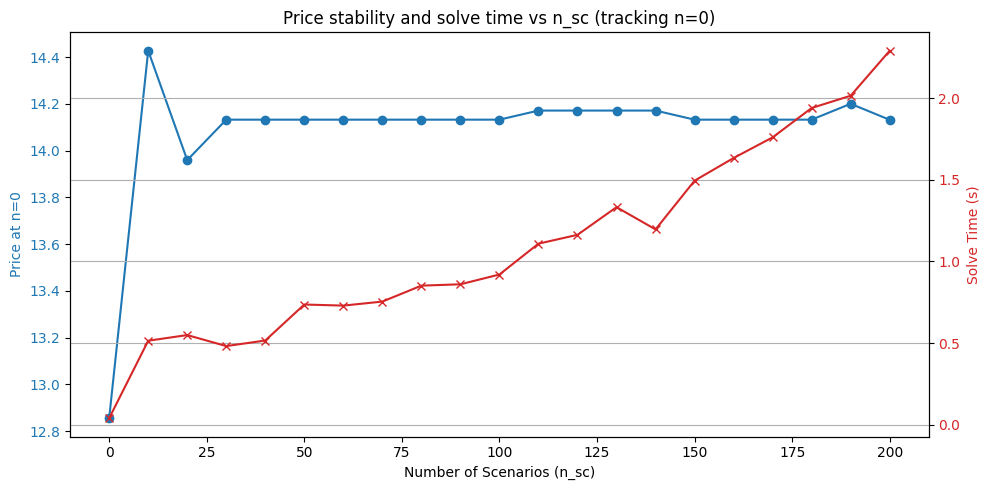

In [89]:
import time

n_preds = 1
n_to_monitor = 0  # which n you want to track

scenario_range = list(range(0, 210, 10))  # try n_sc = 10, 20, ..., 200

price_vals = []
solve_times = []

for n_sc in scenario_range:
    # 1. Build model
    model = model_definition(contextual_var, n_sc, n_preds)

    # 2. Embed constraints and scenarios
    const_embed(model=trainer, opt_model=model, constaints=cons, outcome='demand',
                n_scenarios=n_sc, n_preds=n_preds)

    # 3. Solve model and track time
    opt = pyo.SolverFactory('gurobi_direct')
    opt.options['threads'] = 0
    opt.options['NonConvex'] = 2

    start = time.time()
    results = opt.solve(model, tee=False)
    end = time.time()

    solve_time = end - start
    solve_times.append(solve_time)

    # 4. Extract price value for specific n
    price_val = pyo.value(model.x['price', n_to_monitor])
    price_vals.append(price_val)

    print(f"n_sc={n_sc}: price={price_val:.2f}, time={solve_time:.2f}s")

# --- Plot results ---

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.set_xlabel("Number of Scenarios (n_sc)")
ax1.set_ylabel("Price at n=0", color='tab:blue')
ax1.plot(scenario_range, price_vals, label='Price', color='tab:blue', marker='o')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.set_ylabel("Solve Time (s)", color='tab:red')
ax2.plot(scenario_range, solve_times, label='Time', color='tab:red', marker='x')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title(f"Price stability and solve time vs n_sc (tracking n={n_to_monitor})")
plt.grid(True)
fig.tight_layout()
plt.show()


In [ ]:
import time
import pandas as pd
import matplotlib.pyplot as plt

# Configuration
test_ids = trainer.test_ids[:5]  # Try for first 5 test IDs
scenario_range = list(range(1, 100, 5))  # n_sc = 10, ..., 200

# To store results
results = []

for i, test_id in enumerate(test_ids):
    print("&"*50)
    print(f"Processing ID: {test_id} ({i+1}/{len(test_ids)})")

    # Build contextual_var for this single ID
    contextual_var = trainer.X[trainer.X['id'] == test_id]
    contextual_var = contextual_var.drop_duplicates(subset='id', keep='first').drop(columns='id')
    contextual_var.reset_index(drop=True, inplace=True)
    n_preds = 1  # Because we use one ID at a time

    for n_sc in scenario_range:
        # Define and solve model
        model = model_definition(contextual_var, n_sc, n_preds)
        const_embed(model=trainer, opt_model=model, constaints=cons, outcome='demand',
                    n_scenarios=n_sc, n_preds=n_preds)

        opt = pyo.SolverFactory('gurobi_direct')
        opt.options['threads'] = 0
        opt.options['NonConvex'] = 2

        start = time.time()
        results_obj = opt.solve(model, tee=False)
        end = time.time()

        price_val = pyo.value(model.x['price', 0])
        solve_time = end - start

        results.append({
            'id': test_id,
            'n': 0,
            'n_sc': n_sc,
            'price': price_val,
            'solve_time': solve_time
        })
        print(f"n_sc={n_sc}: price={price_val:.4f}, time={solve_time:.4f}s")
    print("&"*50)

# --- Convert to DataFrame ---
df_results = pd.DataFrame(results)

# --- Plot ---
unique_ids = df_results['id'].unique()
n_cols = 3
n_rows = -(-len(unique_ids) // n_cols)  # Ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4), sharex=False)
axes = axes.flatten()

for i, test_id in enumerate(unique_ids):
    ax1 = axes[i]
    ax2 = ax1.twinx()  # Create second y-axis

    data = df_results[df_results['id'] == test_id]

    # Plot price
    ax1.plot(data['n_sc'], data['price'], color='blue', marker='o', label='Price')
    ax1.set_ylabel('Price', color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')

    # Plot solve time
    ax2.plot(data['n_sc'], data['solve_time'], color='red', marker='x', label='Solve Time')
    ax2.set_ylabel('Solve Time (s)', color='red')
    ax2.tick_params(axis='y', labelcolor='red')

    ax1.set_title(f'ID: {test_id}')
    ax1.set_xlabel('Number of Scenarios (n_sc)')
    ax1.grid(True)

# Remove unused subplots if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Price and Solve Time per ID", y=1.02)
plt.tight_layout()
plt.show()



&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Processing ID: 14 (1/5)
n_sc=1: price=14.9384, time=0.1814s
n_sc=6: price=13.9595, time=0.3753s
n_sc=11: price=14.4275, time=0.4519s
n_sc=16: price=13.9595, time=0.5389s
n_sc=21: price=13.9595, time=0.5182s
n_sc=26: price=14.1325, time=0.4563s
n_sc=31: price=14.1325, time=0.4672s
n_sc=36: price=14.1325, time=0.5576s
n_sc=41: price=14.1325, time=0.5342s
n_sc=46: price=14.1325, time=0.6037s
n_sc=51: price=14.1325, time=0.5948s
n_sc=56: price=14.1325, time=0.6360s
n_sc=61: price=14.1325, time=0.8132s
n_sc=66: price=14.2005, time=0.8208s
n_sc=71: price=14.1325, time=0.8660s
n_sc=76: price=14.1325, time=0.8248s
n_sc=81: price=14.1325, time=0.8940s
n_sc=86: price=14.1325, time=0.9693s
n_sc=91: price=14.1325, time=1.0874s
n_sc=96: price=14.1325, time=1.0774s
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Processing ID: 47 (2/5)
n_sc=1: price=15.1823, time=0.2229s
n_sc=6: price=13.8171, ti